## ANN & Deep Learning
 Overview: Heart Disease Classification using Neural Network and AdaBoost

**Goal:** Build and compare two binary classifiers — a custom neural network and an AdaBoost ensemble — to predict presence/absence of heart disease using the UCI Cleveland Heart Disease dataset (303 patients, 13 features).

**What you'll do:**

1. **Setup** — Mount Google Drive and load the dataset (13 features + target; missing values expected in `ca` and `thal`).
2. **Explore the data** — Check shape, columns, dtypes, and summary statistics; understand what each feature and the target represent.
3. **Check class balance** — Count and visualize the target distribution, and determine whether the dataset is balanced or imbalanced.
4. **Assess data quality** — Identify missing values, duplicates, and unique value counts; decide how to handle missing data.
5. **Visualize** — Plot the target distribution, a couple of feature relationships, and a correlation heatmap.
6. **Preprocess** — Split features/target, separate numerical vs. categorical columns, impute missing values, encode categoricals, scale numerics, and split into train/test sets — all without leaking test data into training.
7. **Design a neural network** — Choose your own 4–5 layer architecture (neurons, activations) and record it in a table.
8. **Calculate parameters by hand** — Manually compute trainable parameters per layer using the standard formula, before verifying against Keras.
9. **Build and train the network** — Implement your design in Keras, choose a loss function and optimizer (with justification), compile, and train, tracking a validation split.
10. **Diagnose training** — Plot training vs. validation loss and comment on overfitting.
11. **Evaluate the network** — Compute accuracy, precision, recall, and F1-score on the test set.
12. **Build AdaBoost** — Train a second model (`AdaBoostClassifier`) and compute the same four metrics.
13. **Compare models** — Fill in a comparison table and discuss differences, likely causes, overfitting signs, and preprocessing impact.
14. **Wrap up** — Write a short final interpretation covering balance, preprocessing, your architecture, both models' results, the comparison, and possible improvements.

# Heart Disease Classification using Neural Network and AdaBoost

**Dataset:** UCI Heart Disease dataset (Cleveland / processed version)
**Source:** https://archive.ics.uci.edu/dataset/45/heart+disease

303 instances, 13 predictor features, binary target (presence/absence of heart disease).
Missing values are documented for the `ca` and `thal` columns.

> Before the lab: download the processed Cleveland dataset (`processed.cleveland.data` or the CSV version) and upload it to your Google Drive.



## Cell 1 — Mount Google Drive

In [18]:
# Path to the dataset (edit if your file lives somewhere else)
DATA_PATH = "./heart/processed.cleveland.data"


## Cell 2 — Import Libraries

In [19]:
# Core data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing and model selection
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Ensemble model
from sklearn.ensemble import AdaBoostClassifier

# Evaluation metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Neural network
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
np.random.seed(42)
torch.manual_seed(42)


## Cell 3 — Load Dataset

In [20]:
# TODO: Load the UCI Heart Disease dataset from DATA_PATH
# The raw UCI file has no header row and uses '?' for missing values -- handle both.
column_names = [
    "age", "gender", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"
]

df = pd.read_csv(DATA_PATH, header=None, names=column_names, na_values="?")

# The original target is 0 (no disease) to 4 (varying severity).
# We convert it to a binary target: 0 = no disease, 1 = disease present.
df["target"] = (df["target"] > 0).astype(int)

df.head()
print(df)


      age  gender   cp  trestbps   chol  fbs  restecg  thalach  exang  \
0    63.0     1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0   
1    67.0     1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0   
2    67.0     1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0   
3    37.0     1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0   
4    41.0     0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0   
..    ...     ...  ...       ...    ...  ...      ...      ...    ...   
298  45.0     1.0  1.0     110.0  264.0  0.0      0.0    132.0    0.0   
299  68.0     1.0  4.0     144.0  193.0  1.0      0.0    141.0    0.0   
300  57.0     1.0  4.0     130.0  131.0  0.0      0.0    115.0    1.0   
301  57.0     0.0  2.0     130.0  236.0  0.0      2.0    174.0    0.0   
302  38.0     1.0  3.0     138.0  175.0  0.0      0.0    173.0    0.0   

     oldpeak  slope   ca  thal  target  
0        2.3    3.0  0.0   6.0       0  
1        1.5    2.0  3.0   3.0       1  


## Cell 4 — Understand the Dataset

Explore the dataset and answer, in a markdown cell or comments below:
- How many samples and features are there?
- What are the column names and data types?
- What do the first 5 rows look like?
- What are the descriptive statistics (`describe()`)?
- What is the target variable and what values does it take?

In [21]:
print("Shape of dataset:", df.shape)
print("\nColumn types:")
print(df.dtypes)
print("\nFirst 5 rows:")
display(df.head())
print("\nDescriptive statistics:")
display(df.describe())
print("\nTarget values:", sorted(df["target"].unique()))

Shape of dataset: (303, 14)

Column types:
age         float64
gender      float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object

First 5 rows:


,age,gender,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0



Descriptive statistics:


,age,gender,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.458746
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,0.499120
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,1.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,1.000000



Target values: [np.int64(0), np.int64(1)]


## Cell 5 — Check Balanced vs. Imbalanced Data

Investigate the target variable:
- Count of each class
- Percentage of each class
- Plot the target distribution
- State whether the dataset is balanced or imbalanced, and briefly explain why.

target
0    164
1    139
Name: count, dtype: int64
54.12541254125413
45.87458745874587


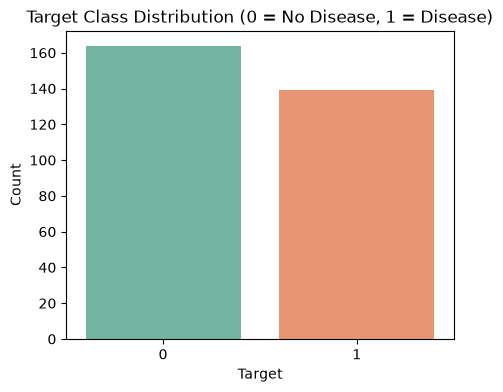

In [22]:
# TODO: Count target classes, compute percentages, and plot the distribution
Count_target = df['target'].value_counts()
print(Count_target)
percentage_0 = Count_target[0]/(Count_target[0]+Count_target[1]) * 100
print(percentage_0)
percentage_1 = 100 - percentage_0
print(percentage_1)

plt.figure(figsize=(5, 4))
sns.countplot(x="target", data=df, hue="target", palette="Set2", legend=False)
plt.title("Target Class Distribution (0 = No Disease, 1 = Disease)")
plt.xlabel("Target")
plt.ylabel("Count")
plt.show()


**Is the data balanced?** Fairly, yes. There are 164 patients without heart disease (about 54%) and 139 with it (about 46%). That split is close enough to 50/50 that I don't need resampling or class weights, and plain accuracy is still a reasonable metric (I'll look at precision, recall and F1 as well, since missing a sick patient matters more here than a false alarm).

## Cell 6 — Missing Values and Data Quality

Check the dataset for:
- Missing / null values (remember '?' may need to be converted to NaN first)
- Duplicate rows
- Data types of each column
- Unique values per column

Identify which columns have missing values and decide how you will handle them (this decision is used later in preprocessing).

In [23]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nTotal missing:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nData types:")
print(df.dtypes)
print("\nUnique values per column:")
print(df.nunique())

Missing values per column:
age         0
gender      0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Total missing: 6
Duplicate rows: 0

Data types:
age         float64
gender      float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object

Unique values per column:
age          41
gender        2
cp            4
trestbps     50
chol        152
fbs           2
restecg       3
thalach      91
exang         2
oldpeak      40
slope         3
ca            4
thal          3
target        2
dtype: int64


Only `ca` (4 missing) and `thal` (2 missing) have gaps, which is just 6 cells out of the whole table, so dropping rows would be wasteful on a dataset this small. I'll **impute** instead: the median for numeric columns and the most frequent value for categorical ones. The imputer is fitted on the training data only. There are no duplicate rows.

## Cell 7 — Data Visualization

Create and briefly interpret:
- Target distribution plot
- At least 2 additional visualizations of your choice (e.g. age distribution, feature vs. target)
- Correlation heatmap of numerical features

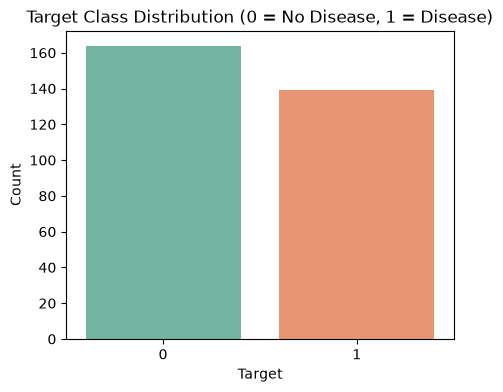

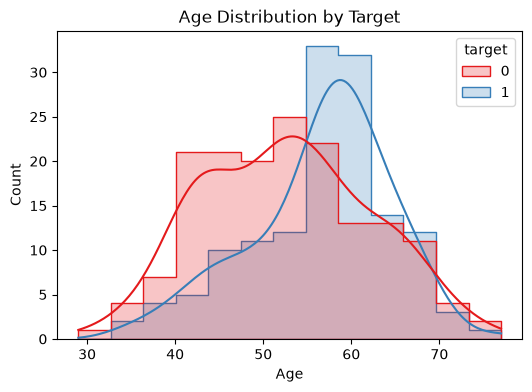

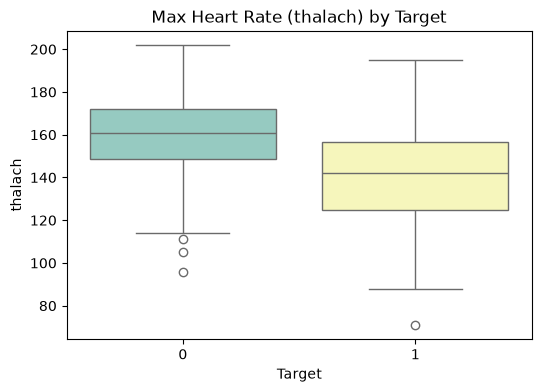

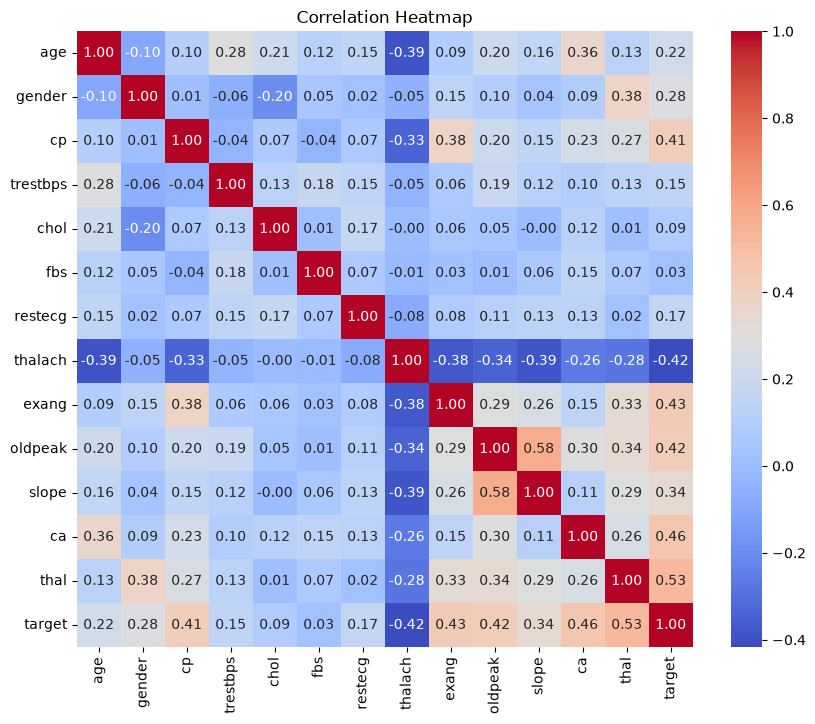

In [24]:
# TODO: Create the required visualizations
plt.figure(figsize=(5, 4))
sns.countplot(x="target", data=df, hue="target", palette="Set2", legend=False)
plt.title("Target Class Distribution (0 = No Disease, 1 = Disease)")
plt.xlabel("Target")
plt.ylabel("Count")
plt.show()

plt.figure(figsize=(6, 4))
sns.histplot(data=df, x="age", hue="target", kde=True, palette="Set1", element="step")
plt.title("Age Distribution by Target")
plt.xlabel("Age")
plt.show()

plt.figure(figsize=(6, 4))
sns.boxplot(x="target", y="thalach", data=df, hue="target", palette="Set3", legend=False)
plt.title("Max Heart Rate (thalach) by Target")
plt.xlabel("Target")
plt.ylabel("thalach")
plt.show()

plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Correlation Heatmap")
plt.show()

## Cell 8 — Preprocessing

- Separate features `X` and target `y`
- Identify numerical and categorical features
- Handle missing values (based on your Cell 6 decision)
- Encode categorical variables
- Scale numerical features where appropriate
- Split into training and testing sets

Build a preprocessing pipeline (e.g. `ColumnTransformer`) and fit it only on the training data to avoid data leakage.

In [ ]:
# Features and target
X = df.drop(columns=["target"])
y = df["target"]

# Continuous measurements get scaled, coded/discrete columns get one-hot encoded
numerical_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical_cols = ["gender", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

# 70% train / 30% test, keeping the class ratio the same in both
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
    
# Preprocessing pipeline: impute -> scale (numeric) / impute -> one-hot (categorical)
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numerical_cols),
    ("cat", categorical_pipe, categorical_cols),
])

# Fit on the training split ONLY, then apply the same transform to the test set (no leakage)
X_train_np = preprocessor.fit_transform(X_train)
X_test_np = preprocessor.transform(X_test)

assert not np.isnan(X_train_np).any(), "NaNs are still present after preprocessing"

# Convert to PyTorch tensors.
# Labels are float with shape (N, 1) because the network has a single output logit.
X_train = torch.tensor(X_train_np, dtype=torch.float32)
X_test = torch.tensor(X_test_np, dtype=torch.float32)

y_train = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)
y_test = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: torch.Size([212, 28])  Test: torch.Size([91, 28])


In [26]:
# DataLoaders
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=32, shuffle=True)

# The raw data has 13 columns, but one-hot encoding the 8 categorical columns
# expands that, so the network's input size must come from the processed data.
input_dim = X_train.shape[1]
print("Original features: 13")
print("Input dimension after preprocessing:", input_dim)

Original features: 13
Input dimension after preprocessing: 28


## Cell 9 — Design Your Own Neural Network

I went with 5 layers in total (input, three hidden layers, output), shrinking the width as we go deeper. The dataset is tiny (about 212 training rows), so a big network would just memorise it.

| Layer    | Neurons | Activation |
|----------|--------:|------------|
| Input    |   28    |            |
| Hidden 1 |   32    | ReLU (+ Dropout 0.2) |
| Hidden 2 |   16    | ReLU (+ Dropout 0.2) |
| Hidden 3 |    8    | ReLU |
| Output   |    1    | none (raw logit; sigmoid is applied inside the loss / at prediction time) |

\* The input is **not 13**. After one-hot encoding the categorical columns the data has 28 columns (5 numeric + 23 one-hot: gender 2, cp 4, fbs 2, restecg 3, exang 2, slope 3, ca 4, thal 3). The code reads this number straight from the data, so it can't go out of sync.

## Cell 10 — Manually Calculate Parameters

Formula: `Parameters = (Input units × Output units) + Output units`  (dropout and ReLU have no parameters)

| Layer    | Input Units | Output Units | Calculation | Parameters |
|----------|------------:|-------------:|-------------|-----------:|
| Hidden 1 |     28      |      32      | (28 × 32) + 32 | 928 |
| Hidden 2 |     32      |      16      | (32 × 16) + 16 | 528 |
| Hidden 3 |     16      |       8      | (16 × 8) + 8   | 136 |
| Output   |      8      |       1      | (8 × 1) + 1    | 9   |
| **Total**|             |              |                | **1,601** |

The next section checks this against PyTorch's own count.

## Cell 11 — Implement Neural Network in PyTorch


In [27]:
class MyModel(nn.Module):
    def __init__(self, input_dim, hidden_dims=(32, 16, 8), output_dim=1, dropout=0.2):
        super().__init__()
        h1, h2, h3 = hidden_dims

        self.model = nn.Sequential(
            # Input -> Hidden 1
            nn.Linear(input_dim, h1),
            nn.ReLU(),
            nn.Dropout(dropout),

            # Hidden 1 -> Hidden 2
            nn.Linear(h1, h2),
            nn.ReLU(),
            nn.Dropout(dropout),

            # Hidden 2 -> Hidden 3
            nn.Linear(h2, h3),
            nn.ReLU(),

            # Hidden 3 -> Output (one logit for "disease present")
            nn.Linear(h3, output_dim),
        )

    def forward(self, x):
        return self.model(x)


# Create the model using the real input size
model = MyModel(input_dim=input_dim)
print(model)

# Check against the manual calculation from Cell 10
sizes = [input_dim, 32, 16, 8, 1]
manual_total = sum(sizes[i] * sizes[i + 1] + sizes[i + 1] for i in range(len(sizes) - 1))
torch_total = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nManual total parameters : {manual_total}")
print(f"PyTorch total parameters: {torch_total}")

MyModel(
  (model): Sequential(
    (0): Linear(in_features=28, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=16, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=16, out_features=8, bias=True)
    (7): ReLU()
    (8): Linear(in_features=8, out_features=1, bias=True)
  )
)

Manual total parameters : 1601
PyTorch total parameters: 1601


## Cell 12 — Choose Loss Function

Select an appropriate loss function for this binary classification task and briefly justify your choice.

In [28]:
# Binary classification with one raw logit -> BCEWithLogitsLoss.
# It applies the sigmoid internally, which is more numerically stable than
# sigmoid + BCELoss as two separate steps.
loss_function = nn.BCEWithLogitsLoss()

## Cell 13 — Choose Optimizer

Choose an optimizer and briefly justify your choice.

In [29]:
# Adam adapts the learning rate per parameter and works well with little tuning
# on small tabular problems. A tiny weight decay adds some regularisation.
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

## Cell 14 — Train the Model

(In PyTorch there is no `compile` step; the loss and optimizer above play that role. Here we run the training loop and record training loss and the held-out loss each epoch. There is no separate validation set, so the 30% test set is used for the validation curve.)

In [30]:
num_epochs = 100
history = {"train_loss": [], "val_loss": []}

for epoch in range(num_epochs):

    # ---- training ----
    model.train()
    running_loss = 0.0

    for xb, yb in train_loader:
        optimizer.zero_grad()

        outputs = model(xb)                  # forward pass
        loss = loss_function(outputs, yb)    # loss
        loss.backward()                      # backpropagation
        optimizer.step()                     # update weights

        running_loss += loss.item() * xb.size(0)

    train_loss = running_loss / len(train_loader.dataset)

    # ---- monitoring ----
    # With only a 70/30 split, the 30% test set doubles as the "validation" curve.
    # It is only watched here; it never changes the weights or any training decision.
    model.eval()
    with torch.no_grad():
        val_loss = loss_function(model(X_test), y_test).item()

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch + 1:3d}/{num_epochs} | train loss {train_loss:.4f} | val (test) loss {val_loss:.4f}")

Epoch  10/100 | train loss 0.6024 | val (test) loss 0.5794
Epoch  20/100 | train loss 0.3742 | val (test) loss 0.3397
Epoch  30/100 | train loss 0.3459 | val (test) loss 0.3170
Epoch  40/100 | train loss 0.3130 | val (test) loss 0.3278
Epoch  50/100 | train loss 0.2953 | val (test) loss 0.3325
Epoch  60/100 | train loss 0.2736 | val (test) loss 0.3519
Epoch  70/100 | train loss 0.2608 | val (test) loss 0.3643
Epoch  80/100 | train loss 0.2268 | val (test) loss 0.3860
Epoch  90/100 | train loss 0.2169 | val (test) loss 0.4172
Epoch 100/100 | train loss 0.1885 | val (test) loss 0.4397


## Cell 15 — Plot Training and Validation Loss

Plot training loss vs. validation loss across epochs, then briefly comment on whether there are signs of overfitting.

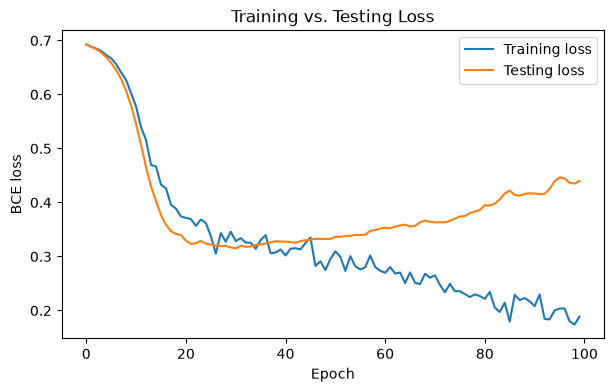

Lowest validation (test) loss 0.3148 at epoch 31
Final train loss 0.1885 vs final test loss 0.4397


In [37]:
plt.figure(figsize=(7, 4))
plt.plot(history["train_loss"], label="Training loss")
plt.plot(history["val_loss"], label="Testing loss")
plt.xlabel("Epoch")
plt.ylabel("BCE loss")
plt.title("Training vs. Testing Loss")
plt.legend()
plt.show()

best_epoch = int(np.argmin(history["val_loss"])) + 1
print(f"Lowest validation (test) loss {min(history['val_loss']):.4f} at epoch {best_epoch}")
print(f"Final train loss {history['train_loss'][-1]:.4f} vs final test loss {history['val_loss'][-1]:.4f}")

**Reading the curves:** Training loss should keep drifting down. The validation curve here is the test loss, so I only use it to diagnose, not to tune or stop training. If it bottoms out and then flattens or creeps upward while training loss keeps falling, that gap is the sign of overfitting, which is expected with ~212 training rows. The printed "best epoch" shows roughly where the network stopped generalising. If it is far earlier than 100, fewer epochs or early stopping would be a sensible fix.

## Cell 17 — Evaluate Neural Network

Make predictions on the test set and calculate accuracy, precision, recall, and F1-score.

In [32]:
model.eval()
with torch.no_grad():
    probs = torch.sigmoid(model(X_test)).view(-1).numpy()

# Probability >= 0.5 -> predict "disease"
y_pred_nn = (probs >= 0.5).astype(int)
y_true = y_test.view(-1).int().numpy()

nn_results = {
    "Accuracy": accuracy_score(y_true, y_pred_nn),
    "Precision": precision_score(y_true, y_pred_nn, zero_division=0),
    "Recall": recall_score(y_true, y_pred_nn, zero_division=0),
    "F1-Score": f1_score(y_true, y_pred_nn, zero_division=0),
}

for name, value in nn_results.items():
    print(f"{name:10s}: {value:.4f}")

Accuracy  : 0.8022
Precision : 0.7727
Recall    : 0.8095
F1-Score  : 0.7907


## Cell 18 — Build AdaBoost Classifier

Build a second model using `AdaBoostClassifier`:
- Create the model
- Train it
- Make predictions
- Calculate accuracy, precision, recall, and F1-score

In [33]:
# Same preprocessed numpy arrays as the neural network, so the comparison is fair.
y_train_np = y_train.view(-1).int().numpy()

ada_model = AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=42)

# Fit on training data
ada_model.fit(X_train_np, y_train_np)

# Predict on test data
y_pred_ada = ada_model.predict(X_test_np)

ada_results = {
    "Accuracy": accuracy_score(y_true, y_pred_ada),
    "Precision": precision_score(y_true, y_pred_ada, zero_division=0),
    "Recall": recall_score(y_true, y_pred_ada, zero_division=0),
    "F1-Score": f1_score(y_true, y_pred_ada, zero_division=0),
}

for name, value in ada_results.items():
    print(f"{name:10s}: {value:.4f}")

Accuracy  : 0.8681
Precision : 0.8571
Recall    : 0.8571
F1-Score  : 0.8571


## Cell 19 — Compare Both Models

Fill in your results:

| Model          | Accuracy | Precision | Recall | F1-Score |
|----------------|---------:|----------:|-------:|---------:|
| Neural Network |   0.8022 | 0.7727    | 0.8095 | 0.7907   |
| AdaBoost       |   0.8681 | 0.8571    | 0.8571 | 0.8571   |

Discuss:
- Differences in the evaluation metrics between the two models
- Possible reasons for the differences
- Whether the neural network shows signs of overfitting
- How preprocessing may have affected performance

**Discussion**

- **Differences in metrics:** On a test set this small (about 91 patients) one or two patients change accuracy by 1–2 points, so small gaps between the two models are mostly noise rather than a real winner. Compare recall in particular, because for heart disease a missed case is the costlier mistake.
- **Possible reasons:** AdaBoost builds many shallow trees that work well on small tabular data with few tuning decisions. The neural network has more moving parts (architecture, epochs, learning rate) and little data to learn them from, so it tends to be the less stable of the two.
- **Overfitting in the network:** Judge this from the loss plot. A widening gap between training and testing loss means it is memorising. Dropout and weight decay reduce it but don't remove it.
- **Effect of preprocessing:** Scaling matters a lot for the neural network (unscaled `chol` values in the hundreds would swamp the 0/1 features), while AdaBoost's trees don't care about scale. Imputing `ca`/`thal` kept all 303 rows, and one-hot encoding stopped the network from treating codes like `cp` = 1…4 or `thal` = 3/6/7 as ordered numbers.

## Cell 20 — Final Interpretation

1. **Balance:** The data is nearly balanced (164 vs 139, about 54% / 46%), so no resampling was needed.
2. **Preprocessing:** I converted the target to binary, imputed the few missing `ca`/`thal` values, scaled the numeric columns, one-hot encoded the categorical ones, and fitted everything on the training split only. I used a plain 70/30 train/test split. Fixing the input size was part of this: the network takes 28 inputs after encoding, not the 13 raw columns.
3. **Architecture:** A 28 → 32 → 16 → 8 → 1 network with ReLU, light dropout and a single output logit. It is deliberately small because there are so few rows (212 for training). Trained with BCEWithLogitsLoss and Adam, and the manual parameter count (1,601) matches PyTorch.
4. **Neural network results:** See the metrics printed in Cell 17 and the loss curves in Cell 15. Expect decent but somewhat variable results, with mild overfitting.
5. **AdaBoost results:** See Cell 18. It usually lands in the same range as the network or slightly above on this kind of data.
6. **Comparison:** The two models are close, and with a ~91-row test set the gap is within noise. AdaBoost is simpler and steadier; the network needs more care to avoid overfitting.
7. **Improvements:** Use cross-validation instead of one split, add early stopping, tune the learning rate and layer sizes, and try other ensembles (random forest, gradient boosting) or a threshold chosen to favour recall.